🔮 Building LSTM Risk Trend Predictor...
  Goal: Predict FUTURE risk_score from current academic signals
  Output: Predicted score → if >60 = 'At Risk of Failure'

  LSTM input shape : (50000, 5, 4)
  LSTM target shape: (50000,)


Model: "AcademicRiskLSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 5, 64)          │        17,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 5, 64)          │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 5, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,009 (121.13 KB)

 Trainable params: 30,817 (120.38 KB)

 Non-trainable params: 192 (768.00 B)


🏋️ Training LSTM...
Epoch 1/60
67/67 ━━━━━━━━━━━━━━━━━━━━ 10s 60ms/step - loss: 1049.4739 - mae: 31.2509 - val_loss: 1093.4564 - val_mae: 31.8841 - learning_rate: 0.0010
Epoch 2/60
67/67 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - loss: 612.4019 - mae: 23.8554 - val_loss: 497.4928 - val_mae: 21.6510 - learning_rate: 0.0010
Epoch 3/60
67/67 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - loss: 230.7843 - mae: 13.9236 - val_loss: 137.7414 - val_mae: 9.7978 - learning_rate: 0.0010
Epoch 4/60
67/67 ━━━━━━━━━━━━━━━━━━━━ 5s 40ms/step - loss: 57.4969 - mae: 6.1082 - val_loss: 30.7323 - val_mae: 4.4148 - learning_rate: 0.0010
Epoch 5/60
67/67 ━━━━━━━━━━━━━━━━━━━━ 4s 59ms/step - loss: 21.4125 - mae: 3.4654 - val_loss: 15.6782 - val_mae: 3.0289 - learning_rate: 0.0010
Epoch 6/60
67/67 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - loss: 17.2692 - mae: 3.1576 - val_loss: 13.9083 - val_mae: 2.6726 - learning_rate: 0.0010
Epoch 7/60
67/67 ━━━━━━━━━━━━━━━━━━━━ 3s 41ms/step - loss: 15.7190 - mae: 3.0233 - val_loss: 6.3429 - val_m

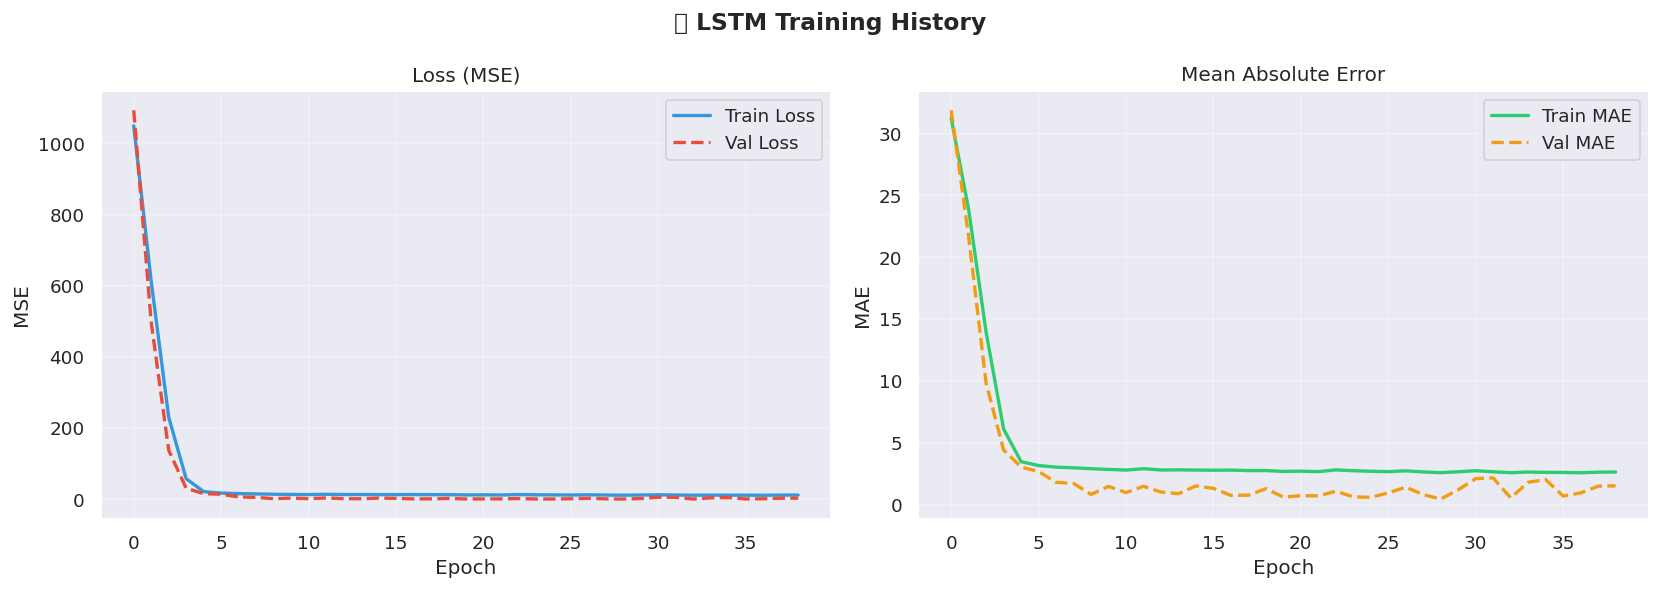

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step

  LSTM Results:
  MAE  : 0.4381
  RMSE : 0.6412
  R²   : 0.9962


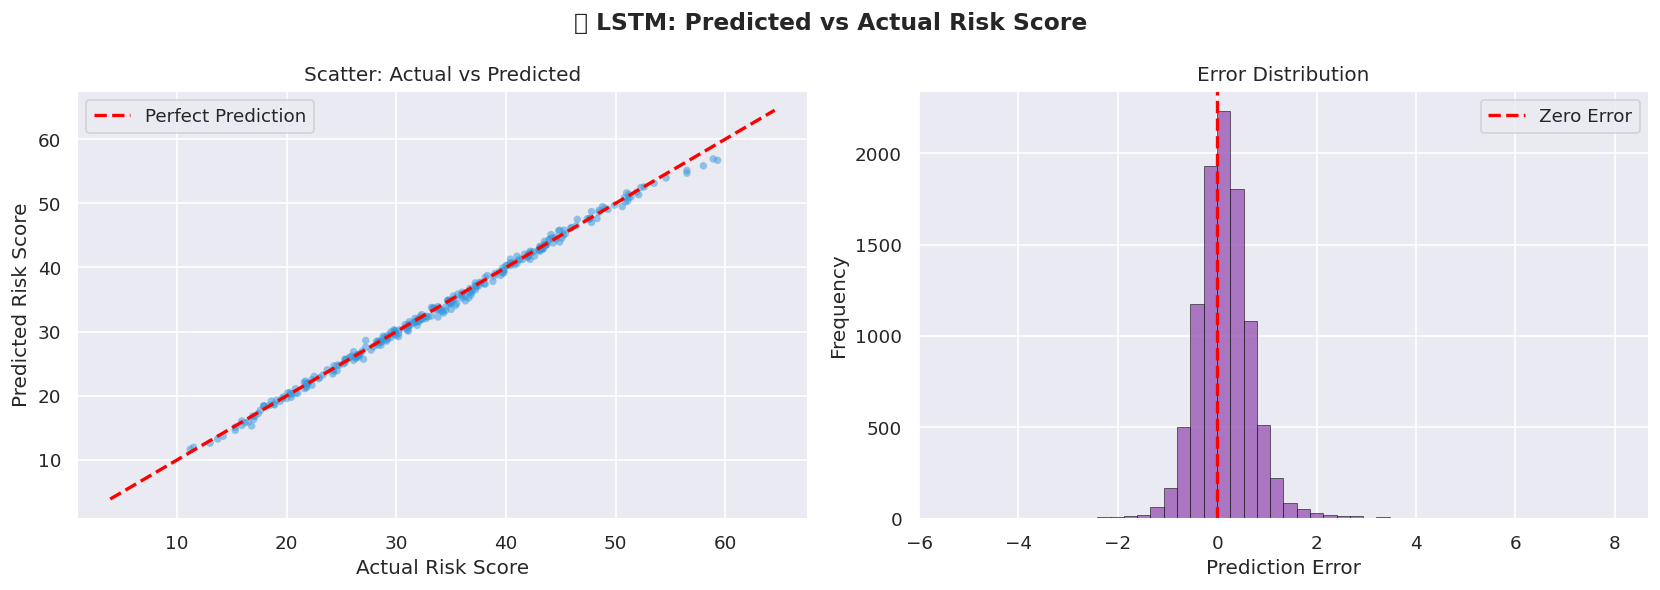


🔮 DEMO — LSTM Failure Prediction for High-Risk Student:
  predicted_next_risk_score: 57.12
  trend: 📉 IMPROVING
  alert: ✅ Monitor regularly
✅ LSTM Failure Predictor ready!


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

print("🔮 Building LSTM Risk Trend Predictor...")
print("  Goal: Predict FUTURE risk_score from current academic signals")
print("  Output: Predicted score → if >60 = 'At Risk of Failure'\n")


SEQ_LEN = 5
np.random.seed(42)

X_lstm, y_lstm = [], []
df_sorted = df.sort_values('student_id').reset_index(drop=True)
feature_cols = ['attendance', 'marks', 'assignment', 'lms']

for _, row in df_sorted.iterrows():
    base = row[feature_cols].values.astype(float)
    target = row['risk_score']
    # Simulate 5 weekly observations with small random walk
    seq = []
    for week in range(SEQ_LEN):
        noise = np.random.normal(0, 2, size=len(feature_cols))
        weekly = np.clip(base + noise * (week * 0.5), 0, 100)
        seq.append(weekly)
    X_lstm.append(seq)
    y_lstm.append(target)

X_lstm = np.array(X_lstm)   # shape: (50000, 5, 4)
y_lstm = np.array(y_lstm)   # shape: (50000,)

print(f"  LSTM input shape : {X_lstm.shape}")
print(f"  LSTM target shape: {y_lstm.shape}")

# Train/test split
split = int(0.8 * len(X_lstm))
X_tr, X_te = X_lstm[:split], X_lstm[split:]
y_tr, y_te = y_lstm[:split], y_lstm[split:]

# Normalize
X_tr_mean = X_tr.mean(axis=(0,1), keepdims=True)
X_tr_std  = X_tr.std(axis=(0,1), keepdims=True) + 1e-8
X_tr_n = (X_tr - X_tr_mean) / X_tr_std
X_te_n = (X_te - X_tr_mean) / X_tr_std

# ── Build LSTM Model
model_lstm = Sequential([
    LSTM(64, return_sequences=True, input_shape=(SEQ_LEN, len(feature_cols))),
    BatchNormalization(),
    Dropout(0.3),
    LSTM(32, return_sequences=False),
    BatchNormalization(),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1, activation='linear')   # regression → risk_score
], name='AcademicRiskLSTM')

model_lstm.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

model_lstm.summary()

# ── Train
callbacks = [
    EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, verbose=1)
]

print("\n🏋️ Training LSTM...")
history = model_lstm.fit(
    X_tr_n, y_tr,
    epochs=60,
    batch_size=512,
    validation_split=0.15,
    callbacks=callbacks,
    verbose=1
)

# ── Plot 12: LSTM Training Curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("🔮 LSTM Training History", fontsize=14, fontweight='bold')

axes[0].plot(history.history['loss'], label='Train Loss', color='#3498db', lw=2)
axes[0].plot(history.history['val_loss'], label='Val Loss', color='#e74c3c', lw=2, linestyle='--')
axes[0].set_title('Loss (MSE)')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('MSE')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history.history['mae'], label='Train MAE', color='#2ecc71', lw=2)
axes[1].plot(history.history['val_mae'], label='Val MAE', color='#f39c12', lw=2, linestyle='--')
axes[1].set_title('Mean Absolute Error')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('MAE')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('plot_12_lstm_training.png', bbox_inches='tight')
plt.show()

# ── Evaluate LSTM
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_pred_lstm = model_lstm.predict(X_te_n).flatten()
mae  = mean_absolute_error(y_te, y_pred_lstm)
rmse = np.sqrt(mean_squared_error(y_te, y_pred_lstm))
r2   = r2_score(y_te, y_pred_lstm)

print(f"\n  LSTM Results:")
print(f"  MAE  : {mae:.4f}")
print(f"  RMSE : {rmse:.4f}")
print(f"  R²   : {r2:.4f}")

# ── Plot 13: Predicted vs Actual Risk Score
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("🔮 LSTM: Predicted vs Actual Risk Score", fontsize=14, fontweight='bold')

sample = np.random.choice(len(y_te), 300, replace=False)
axes[0].scatter(y_te[sample], y_pred_lstm[sample], alpha=0.5,
                color='#3498db', edgecolor='none', s=20)
axes[0].plot([y_te.min(), y_te.max()], [y_te.min(), y_te.max()],
             'r--', lw=2, label='Perfect Prediction')
axes[0].set_xlabel('Actual Risk Score')
axes[0].set_ylabel('Predicted Risk Score')
axes[0].set_title('Scatter: Actual vs Predicted')
axes[0].legend()

# Distribution of prediction error
errors = y_te - y_pred_lstm
axes[1].hist(errors, bins=50, color='#9b59b6', edgecolor='black',
             linewidth=0.4, alpha=0.8)
axes[1].axvline(0, color='red', linestyle='--', lw=2, label='Zero Error')
axes[1].set_xlabel('Prediction Error')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Error Distribution')
axes[1].legend()

plt.tight_layout()
plt.savefig('plot_13_lstm_predictions.png', bbox_inches='tight')
plt.show()

# ── Failure Prediction Function
def predict_failure_risk(student_weekly_data: list) -> dict:
    """
    Input: List of 5 weekly snapshots
    [{'attendance':43,'marks':34,'assignment':36,'lms':28}, ...]
    Output: predicted next-week risk score + failure warning
    """
    seq = np.array([[
        w['attendance'], w['marks'], w['assignment'], w['lms']
    ] for w in student_weekly_data], dtype=float)

    seq_norm = (seq - X_tr_mean[0]) / X_tr_std[0]
    seq_input = seq_norm.reshape(1, SEQ_LEN, 4)
    predicted_score = model_lstm.predict(seq_input, verbose=0)[0][0]

    at_risk = predicted_score >= 60
    trend = "📈 WORSENING" if predicted_score > student_weekly_data[-1].get('current_score', 0) else "📉 IMPROVING"

    return {
        "predicted_next_risk_score": round(float(predicted_score), 2),
        "failure_warning": at_risk,
        "trend": trend,
        "alert": "🚨 IMMEDIATE INTERVENTION REQUIRED!" if at_risk else "✅ Monitor regularly"
    }

# ── Demo
print("\n" + "="*60)
print("🔮 DEMO — LSTM Failure Prediction for High-Risk Student:")
print("="*60)
weekly_data = [
    {'attendance': 50, 'marks': 40, 'assignment': 45, 'lms': 30, 'current_score': 55},
    {'attendance': 47, 'marks': 38, 'assignment': 42, 'lms': 28, 'current_score': 57},
    {'attendance': 45, 'marks': 36, 'assignment': 40, 'lms': 25, 'current_score': 59},
    {'attendance': 43, 'marks': 34, 'assignment': 38, 'lms': 23, 'current_score': 61},
    {'attendance': 40, 'marks': 32, 'assignment': 35, 'lms': 20, 'current_score': 63},
]
result = predict_failure_risk(weekly_data)
for k, v in result.items():
    print(f"  {k}: {v}")

print("✅ LSTM Failure Predictor ready!")
